# Homework 1: Option Basics and the Black–Scholes–Merton Model


This notebook implements the four parts of Assignment 1:
1. **(a)** A customizable plotter and a demonstration.
2. **(b)** European call pricing with five Greeks.
3. **(c)** European put pricing, with optional Greeks.
4. **(d)** A numerical check of put–call parity.



## Setup
Use NumPy for numerical calculations, Matplotlib for plots and SciPy for the standard normal distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

The lecture hard-codes the figure size, font sizes, line style and width. These are now configurable through the layout dictionary.

Additional options include y-axis labels, axis limits, grid, colors, markers, legend position and saving a figure. The function supports one or several curves and returns the figure and axes.

In [2]:
def my_plotter(x, y, layout=None, names=None):
    """Plot one curve or a sequence of curves against a shared x array."""
    layout = {} if layout is None else dict(layout)
    x = np.asarray(x)
    y = np.asarray(y)
    if y.ndim == 1:
        y = y[np.newaxis, :]
    if x.ndim != 1 or y.ndim != 2 or y.shape[1] != x.size:
        raise ValueError("Use a 1D x array and curves with the same length as x.")
    if names is not None and len(names) != len(y):
        raise ValueError("Provide one name per curve.")
    colors = layout.get("colors")
    if colors is not None and len(colors) < len(y):
        raise ValueError("Provide at least one color per curve.")
    fig, ax = plt.subplots(figsize=layout.get("figsize", (9, 5)))
    for i, curve in enumerate(y):
        ax.plot(x, curve,
                label=None if names is None else names[i],
                color=None if colors is None else colors[i],
                linewidth=layout.get("linewidth", 2),
                linestyle=layout.get("styles", ["-"])[
                    i % len(layout.get("styles", ["-"]))],
                marker=layout.get("marker", None),
                alpha=layout.get("alpha", 1.0))
    ax.set_title(layout.get("title", ""),
                 fontsize=layout.get("title_fontsize", 16),
                 pad=layout.get("titlepad", 15))
    ax.set_xlabel(layout.get("x_label", ""), fontsize=layout.get("label_fontsize", 12))
    ax.set_ylabel(layout.get("y_label", ""), fontsize=layout.get("label_fontsize", 12))
    ax.tick_params(labelsize=layout.get("tick_fontsize", 10))
    ax.grid(layout.get("grid", True), alpha=0.3)
    if layout.get("zero_line", True):
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    if "xlim" in layout:
        ax.set_xlim(layout["xlim"])
    if "ylim" in layout:
        ax.set_ylim(layout["ylim"])
    if names is not None and layout.get("legend", True):
        ax.legend(loc=layout.get("legend_loc", "best"),
                  fontsize=layout.get("legend_fontsize", 10))
    fig.tight_layout()
    if layout.get("save_path"):
        fig.savefig(layout["save_path"], dpi=layout.get("dpi", 150), bbox_inches="tight")
    plt.show()
    return fig, ax

### Demonstration
Plot a parabola, a straight line and a sine wave with different colors and line styles. This is a visual demonstration of the plotting options.

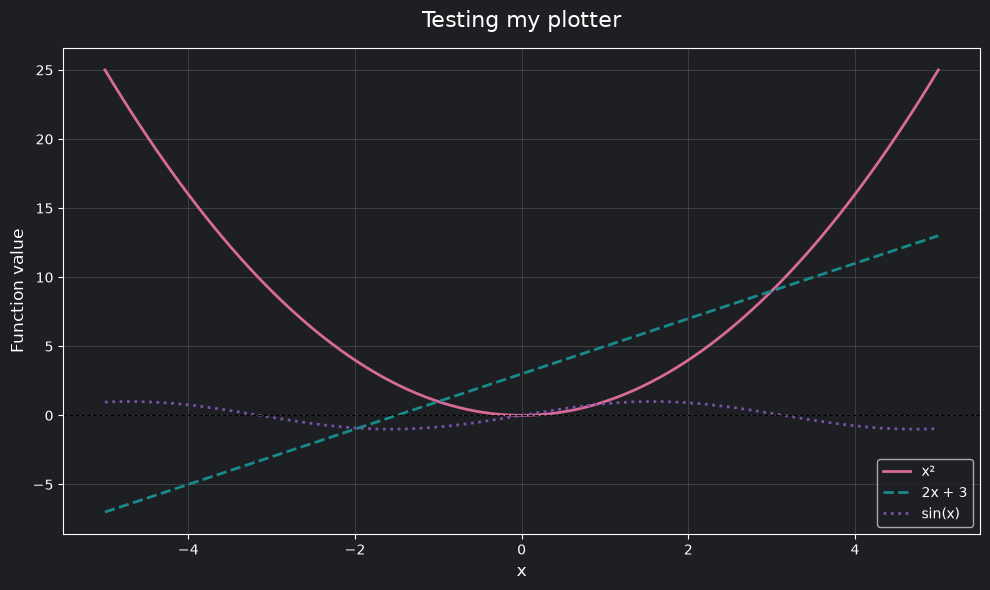

In [3]:
def test_my_plotter():
    x = np.linspace(-5, 5, 100)

    my_plotter(
        x,
        [x**2, 2*x + 3, np.sin(x)],
        names=["x²", "2x + 3", "sin(x)"],
        layout={
            "title": "Testing my plotter",
            "x_label": "x",
            "y_label": "Function value",
            "figsize": (10, 6),
            "colors": ["#D76A99", "#178B8B", "#7851A9"],
            "linewidth": 2,
            "grid": True,
            "styles": ["-", "--", ":"],
        },
    )

test_my_plotter()

## (b) Call pricing and Greeks
Assume European exercise, no dividends, and constant interest rate and volatility.

| Input | Meaning | Convention |
|---|---|---|
| `S0` | Current stock price | Positive |
| `K` | Strike price | Positive |
| `T` | Remaining time to maturity | Years, strictly positive |
| `r` | Continuously compounded risk-free rate | Decimal, e.g. 0.05 = 5% |
| `sigma` | Annual volatility | Positive decimal, e.g. 0.20 = 20% |

Define
$$d_1=\frac{\ln(S_0/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}},\qquad d_2=d_1-\sigma\sqrt{T}.$$
The call price is
$$C=S_0N(d_1)-Ke^{-rT}N(d_2),$$
where `norm.cdf` evaluates $N$ and `norm.pdf` evaluates its density $\phi$.

### Shared input preparation
This helper converts inputs to compatible NumPy arrays, checks their values and calculates $d_1,d_2$. Both pricers use it. Zero maturity and zero volatility require separate limiting formulas and are excluded here.

In [5]:
def _bsm_inputs(r, T, S0, sigma, K):
    r, T, S0, sigma, K = np.broadcast_arrays( *[np.asarray(v, dtype=float) for v in (r, T, S0, sigma, K)])
    if not all(np.all(np.isfinite(v)) for v in (r, T, S0, sigma, K)):
        raise ValueError("All inputs must be finite.")
    if any(np.any(v <= 0) for v in (T, S0, sigma, K)):
        raise ValueError("T, S0, sigma and K must be strictly positive.")
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return r, T, S0, sigma, K, d1, d2

### European call pricer
Set `return_greeks=True` to return a dictionary with the price and Greeks; otherwise only the price is returned.

| Greek | Sensitivity |
|---|---|
| Delta | Price sensitivity to the stock price |
| Gamma | Change in delta with the stock price |
| Vega | Price sensitivity to volatility |
| Theta | Price sensitivity to calendar time passing |
| Rho | Price sensitivity to the interest rate |

**Units:** vega and rho are per unit change in volatility and rate; multiply by 0.01 for a one percentage point change. Theta is per year and equals minus the derivative with respect to remaining maturity.

In [6]:
def black_scholes_eur_call(r, T, S0, sigma, K, return_greeks=False):
    r, T, S0, sigma, K, d1, d2 = _bsm_inputs(r, T, S0, sigma, K)
    discount = np.exp(-r * T)
    price = S0 * norm.cdf(d1) - K * discount * norm.cdf(d2)
    if not return_greeks:
        return price
    return {
        "price": price,
        "delta": norm.cdf(d1),
        "gamma": norm.pdf(d1) / (S0 * sigma * np.sqrt(T)),
        "vega": S0 * norm.pdf(d1) * np.sqrt(T),
        "theta": -S0 * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
                 - r * K * discount * norm.cdf(d2),
        "rho": K * T * discount * norm.cdf(d2)
    }

### Call example
Choose an at-the-money contract: current spot and strike both equal 100, with one year remaining, a 5% interest rate and 20% volatility.

In [7]:
parameters = dict(r=0.05, T=1.0, S0=100.0, sigma=0.20, K=100.0)

call_result = black_scholes_eur_call(**parameters, return_greeks=True)

for name, value in call_result.items():
    print(f"Call {name:>5}: {float(value):.6f}")

Call price: 10.450584
Call delta: 0.636831
Call gamma: 0.018762
Call  vega: 37.524035
Call theta: -6.414028
Call   rho: 53.232482


## (c) European put pricer
The direct BSM formula for the European put is
$$P=Ke^{-rT}N(-d_2)-S_0N(-d_1).$$
The put is implemented independently of put–call parity, so the later parity example compares the two pricing formulas. Optional put Greeks are also included.

In [8]:
def black_scholes_eur_put(r, T, S0, sigma, K, return_greeks=False):
    r, T, S0, sigma, K, d1, d2 = _bsm_inputs(r, T, S0, sigma, K)
    discount = np.exp(-r * T)
    price = K * discount * norm.cdf(-d2) - S0 * norm.cdf(-d1)
    if not return_greeks:
        return price
    return {
        "price": price,
        "delta": norm.cdf(d1) - 1,
        "gamma": norm.pdf(d1) / (S0 * sigma * np.sqrt(T)),
        "vega": S0 * norm.pdf(d1) * np.sqrt(T),
        "theta": -S0 * norm.pdf(d1) * sigma / (2 * np.sqrt(T))+ r * K * discount * norm.cdf(-d2),
        "rho": -K * T * discount * norm.cdf(-d2)
    }

### Put example: the same contract
Use the same parameters as the call example, and label each printed Greek.

In [9]:
put_result = black_scholes_eur_put(**parameters, return_greeks=True)

for name, value in put_result.items():
    print(f"Put  {name:>5}: {float(value):.6f}")

Put  price: 5.573526
Put  delta: -0.363169
Put  gamma: 0.018762
Put   vega: 37.524035
Put  theta: -1.657880
Put    rho: -41.890461


### Additional put example
Keep the separate example from the original code: spot 20, strike 100, 30% volatility and one year remaining. This put is deeply in the money, so its price is much higher than the at-the-money put above.

In [10]:
additional_put_price = black_scholes_eur_put(
    r=0.05, T=1.0, S0=20.0, sigma=0.30, K=100.0
)
print(f"Additional put price (S0=20, K=100): {float(additional_put_price):.6f}")

Additional put price (S0=20, K=100): 75.122943


## (d) Numerical check of put–call parity
For a European call and put with identical parameters on a non-dividend-paying stock,
$$C-P=S_0-Ke^{-rT}.$$
At maturity, a long call plus a short put pays $S_T-K$. Owning the stock and borrowing the present value of $K$ produces the same payoff, so these portfolios have the same present value.

Calculate both sides for the original at-the-money example. `np.isclose` allows a small tolerance for floating-point rounding.

In [12]:
r = 0.05
T = 1.0
S0 = 100.0
sigma = 0.20
K = 100.0

call_price = black_scholes_eur_call(r, T, S0, sigma, K)
put_price = black_scholes_eur_put(r, T, S0, sigma, K)

left_side = call_price - put_price
right_side = S0 - K * np.exp(-r * T)

print("Call price:", call_price)
print("Put price:", put_price)
print("C - P:", left_side)
print("S0 - K exp(-rT):", right_side)
print("Difference:", left_side - right_side)

if np.isclose(left_side, right_side):
    print("Put–call parity holds.")
else:
    print("Put–call parity does not hold.")

Call price: 10.450583572185565
Put price: 5.573526022256971
C - P: 4.877057549928594
S0 - K exp(-rT): 4.877057549928594
Difference: 0.0
Put–call parity holds.


## Results
- The plotter demonstrates configurable colors, labels, line styles and figure size.
- The call and put functions return prices and optional Greeks.
- For the at-the-money example, the call price is approximately **10.450584** and the put price is **5.573526**.
- Both sides of put–call parity equal approximately **4.87705755**. The numerical example therefore agrees with the theoretical identity.